# 实验 1：探索原始南瓜数据

## Step 1：读取 CSV 文件
这里的 pumpkins 是一个 Pandas DataFrame，可以理解为 Python 中的二维数据表
DataFrame 有三个值得关注的组成部分：
- 行（Row）：一条数据记录。
- 列（Column）：一个字段或变量。
- 索引（Index）：用于定位行的标签。

In [1]:
import pandas as pd

pumpkins = pd.read_csv("../../data/US-pumpkins.csv")

print("数据形状", pumpkins.shape)
display(pumpkins.head(5))

数据形状 (1757, 26)


,City Name,Type,Package,Variety,Sub Variety,Grade,Date,Low Price,High Price,Mostly Low,...,Unit of Sale,Quality,Condition,Appearance,Storage,Crop,Repack,Trans Mode,Unnamed: 24,Unnamed: 25
0,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,4/29/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
1,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,5/6/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
2,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
3,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
4,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,11/5/16,90.0,100.0,90.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN


## Step 2：检查缺失值

`pumpkins.isnull()` 会检查整个数据表中的每个单元格，缺失就标记为 `True`，否则标记为 `False`

因为 Python 中的布尔值参与求和时，`True` 计为 1，`False` 计为 0。因此，`.sum()` 会统计每一列中有多少个缺失值。

In [2]:
pumpkins.isnull().sum()

City Name             0
Type               1712
Package               0
Variety               5
Sub Variety        1461
Grade              1757
Date                  0
Low Price             0
High Price            0
Mostly Low          103
Mostly High         103
Origin                3
Origin District    1626
Item Size           279
Color               616
Environment        1757
Unit of Sale       1595
Quality            1757
Condition          1757
Appearance         1757
Storage            1757
Crop               1757
Repack                0
Trans Mode         1757
Unnamed: 24        1757
Unnamed: 25        1654
dtype: int64

## Step 3：筛选需要的列

`:` 表示选择所有行，而 `columns_to_select` 指定需要保留的列

In [3]:
colunms_to_select = ['Package', 'Low Price', 'High Price', 'Date']

pumpkins = pumpkins.loc[:, colunms_to_select]
pumpkins.head()

,Package,Low Price,High Price,Date
0,24 inch bins,270.0,280.0,4/29/17
1,24 inch bins,270.0,280.0,5/6/17
2,24 inch bins,160.0,160.0,9/24/16
3,24 inch bins,160.0,160.0,9/24/16
4,24 inch bins,90.0,100.0,11/5/16


# 实验 2：构造新的价格与月份字段

下一步从原始字段中创建两个新变量：
- Price：使用最高价和最低价的平均值，作为本次实验的价格代表值。
- Month：从日期中提取月份。

## Step 1：计算价格

In [4]:
price = (pumpkins['Low Price'] + pumpkins['High Price']) / 2

price.head()

0    275.0
1    275.0
2    160.0
3    160.0
4     95.0
dtype: float64

## Step 2：提取月份

`pd.DatetimeIndex()` 将日期转换为 Pandas 可处理的日期索引，`.month` 则提取其中的月份数字。

In [5]:
month = pd.DatetimeIndex(pumpkins['Date']).month

month[:5]

Index([4, 5, 9, 9, 11], dtype='int32', name='Date')

## Step 3：创建新的 DataFrame

In [6]:
new_pumpkins = pd.DataFrame({
    'Month': month,
    'Package': pumpkins['Package'], 
    'Low Price': pumpkins['Low Price'],
    'High Price': pumpkins['High Price'],
    'Price': price
    })

new_pumpkins.head()

,Month,Package,Low Price,High Price,Price
0,4,24 inch bins,270.0,280.0,275.0
1,5,24 inch bins,270.0,280.0,275.0
2,9,24 inch bins,160.0,160.0,160.0
3,9,24 inch bins,160.0,160.0,160.0
4,11,24 inch bins,90.0,100.0,95.0


# 实验 3：筛选 bushel 包装数据

南瓜数据集存在多种包装方式，例如按个、按箱以及按蒲式耳销售

不区分包装，比较它们的价格就可能产生误导，先只保留包装名称包含 `bushel` 的记录

## Step 1：观察 Package 列

`value_counts()` 用于统计某一列中每个不同值出现的次数。

In [7]:
pumpkins['Package'].value_counts()

Package
36 inch bins            663
24 inch bins            551
1/2 bushel cartons      234
1 1/9 bushel cartons    117
35 lb cartons            42
bushel cartons           37
40 lb cartons            19
1 1/9 bushel crates      17
each                     17
bins                     13
50 lb sacks              11
50 lb cartons            10
bushel baskets           10
22 lb cartons            10
20 lb cartons             6
Name: count, dtype: int64

## Step 2：筛选包含 bushel 的记录

布尔筛选（Boolean Filtering）

In [8]:
pumpkins = pumpkins[pumpkins['Package'].str.contains('bushel', case=True, regex=False, na=False)]

print("筛选后的数据形状", pumpkins.shape)
pumpkins['Package'].value_counts()

筛选后的数据形状 (415, 4)


Package
1/2 bushel cartons      234
1 1/9 bushel cartons    117
bushel cartons           37
1 1/9 bushel crates      17
bushel baskets           10
Name: count, dtype: int64

## Step 3：重新生成整理后的 DataFrame

因为我们刚刚改变了 `pumpkins` 的行数，所以此前计算的 `month`、`price` 和 `new_pumpkins` 需要重新生成。

In [9]:
colunms_to_select = ['Package', 'Low Price', 'High Price', 'Date']

new_pumpkins = pumpkins.loc[:, colunms_to_select]

price = (new_pumpkins['Low Price'] + new_pumpkins['High Price']) / 2
month = pd.DatetimeIndex(new_pumpkins['Date']).month

new_pumpkins = pd.DataFrame({
    'Month': month,
    'Package': new_pumpkins['Package'], 
    'Low Price': new_pumpkins['Low Price'],
    'High Price': new_pumpkins['High Price'],
    'Price': price
    })

new_pumpkins.head()

,Month,Package,Low Price,High Price,Price
70,9,1 1/9 bushel cartons,15.0,15.0,15.0
71,9,1 1/9 bushel cartons,18.0,18.0,18.0
72,10,1 1/9 bushel cartons,18.0,18.0,18.0
73,10,1 1/9 bushel cartons,17.0,17.0,17.0
74,10,1 1/9 bushel cartons,15.0,15.0,15.0


# 实验 4：单位价格标准化

虽然只保留了 `bushel 包装`，但仍然存在两种不同的包装体积：
- `1 1/9 bushel`：约 1.111 个蒲式耳
- `1/2 bushel`：0.5 个蒲式耳

这时就需要把价格统一为 美元 / bushel

## Step 1：理解单位价格换算

$$
 \text{标准化价格} = \frac{\text{包装价格}}{\text{包装体积}} 
$$

这里 loc 出现了一个新的用法：

`new_pumpkins.loc[条件, 'Price'] = 新值` 

来根据条件修改指定列中的数据

In [10]:
new_pumpkins.loc[new_pumpkins['Package'].str.contains('1 1/9'), 'Price'] = price / (1 + 1/9)
new_pumpkins.loc[new_pumpkins['Package'].str.contains('1/2'), 'Price'] = price / (1/2)

new_pumpkins.head()

,Month,Package,Low Price,High Price,Price
70,9,1 1/9 bushel cartons,15.0,15.0,13.5
71,9,1 1/9 bushel cartons,18.0,18.0,16.2
72,10,1 1/9 bushel cartons,18.0,18.0,16.2
73,10,1 1/9 bushel cartons,17.0,17.0,15.3
74,10,1 1/9 bushel cartons,15.0,15.0,13.5


# 实验5：Matplotlib 数据可视化

先使用 Matplotlib 绘制散点图，然后在分组绘制柱状图

## Step1：绘制散点图

`plot(x, y)`

`x`表示横轴，`y`表示纵轴，这里横轴是价格，纵轴是月份

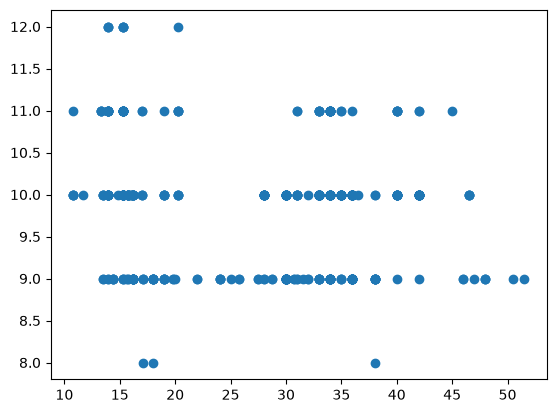

In [11]:
import matplotlib.pyplot as plt

price = new_pumpkins.Price
month = new_pumpkins.Month

plt.scatter(price, month)
plt.show()

换一种表示方法，两个版本数据没有变化，只是改变了坐标轴

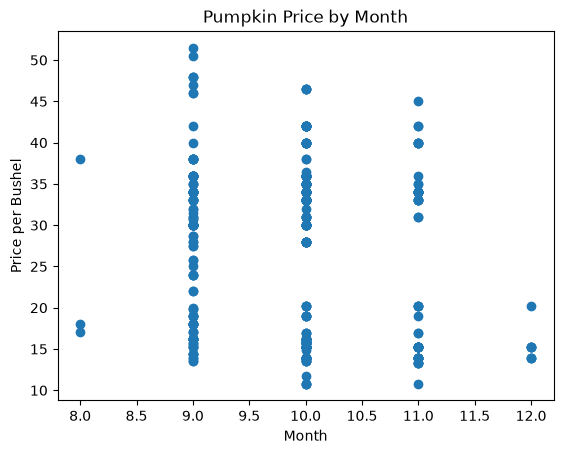

In [12]:
plt.scatter(month, price)

plt.xlabel("Month")
plt.ylabel("Price per Bushel")
plt.title("Pumpkin Price by Month")

plt.show()

## Step2：按月份分组并计算平均价格

两个关键操作：
* `groupby('Month')`：把相同月份的数据分为一组
* `mean()`：分别计算每个月的平均价格

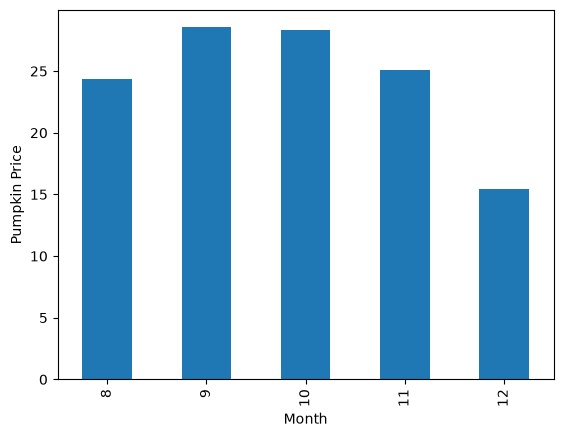

In [14]:
new_pumpkins.groupby(['Month'])['Price'].mean().plot(kind='bar')

plt.ylabel("Pumpkin Price")
plt.show()

# 实验6：使用 Seaborn

Seaborn适合快速制作统计图表

## Step1：绘制分组柱状图

和刚才 `groupby()`相比，Seaborn 会自动计算每个类别的均值，并显示用于反映估计不确定性的误差线

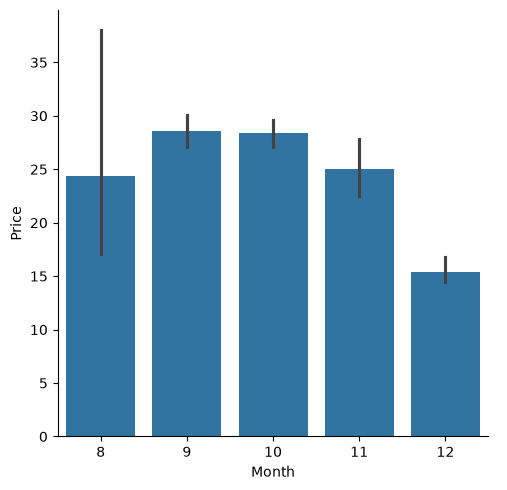

In [15]:
import seaborn as sns

sns.catplot(x='Month', y='Price', data=new_pumpkins, kind='bar')

plt.show()

## Step2：绘制相关性热力图

热力图中的相关系数通常在 -1 到 1 之间，相关性反映的是线性关系，而不是所有类型的关系：
| 相关系数 | 含义 |
| :--- | :--- |
| 接近 1 | 强正线性相关 |
| 接近 0 | 线性相关程度弱 |
| 接近 -1 | 强负线性相关 |

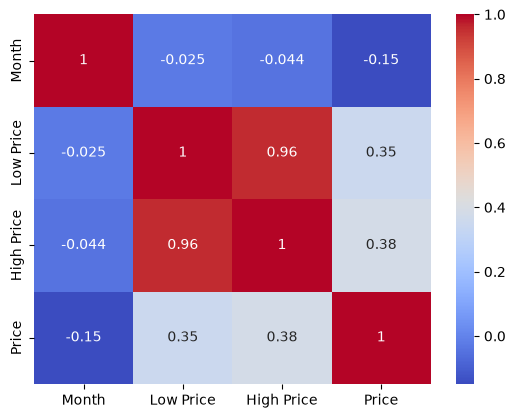

In [17]:
correlation = new_pumpkins[
    ['Month', 'Low Price', 'High Price', 'Price']
].corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm')

plt.show()

# Assignment：Exploring Visualizations

使用本节的南瓜数据，通过 Matplotlib 和 Seaborn 制作可视化，并比较哪一个库更容易使用。

继续使用之前完成清洗的 `new_pumpkins`

In [18]:
print(new_pumpkins.shape)
print(new_pumpkins[['Month', 'Price']].head())

print(new_pumpkins[['Month', 'Price']].isnull().sum())

(415, 5)
    Month  Price
70      9   13.5
71      9   16.2
72     10   16.2
73     10   15.3
74     10   13.5
Month    0
Price    0
dtype: int64


## 实验A：用 Matplotlib 分析价格趋势

把单条记录的散点和每个月的平均价格绘制在同一张图上。

`plt.plot()` 把每个月的平均价格连接起来，方便观察变化趋势。连接线只是为了展示相邻月份的均值变化，不代表已经训练出了回归模型

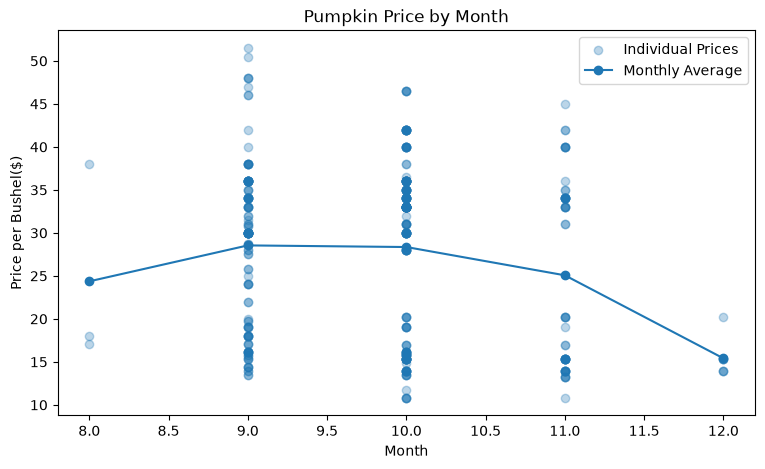

In [20]:
import matplotlib.pyplot as plt

monthly_mean = new_pumpkins.groupby(['Month'])['Price'].mean()

plt.figure(figsize=(9, 5))

plt.scatter(new_pumpkins['Month'], new_pumpkins['Price'], alpha=0.3, label='Individual Prices')
plt.plot(monthly_mean.index, monthly_mean.values, marker='o', label='Monthly Average')

plt.xlabel("Month")
plt.ylabel("Price per Bushel($)")
plt.title("Pumpkin Price by Month")
plt.legend()
plt.show()

# 实验 B：用 Seaborn 分析价格分布

用箱线图观察各月份的价格分布。

箱线图中最值得关注的是：
- 箱体中间的线：中位数。
- 箱体：中间 50% 数据所在的范围。
- 须线：显示非异常值的延伸范围，默认通常使用 1.5 倍四分位距规则。
- 单独显示的点：潜在异常值，不代表一定是错误数据。

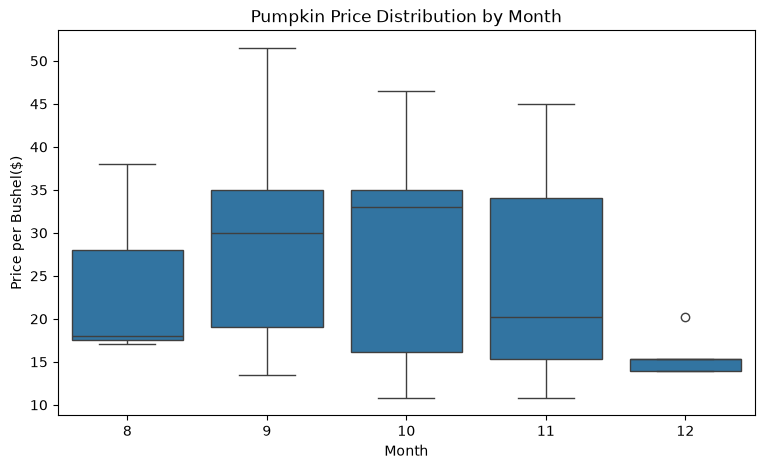

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

sns.boxplot(data=new_pumpkins, x='Month', y='Price')

plt.xlabel("Month")
plt.ylabel("Price per Bushel($)")
plt.title("Pumpkin Price Distribution by Month")
plt.show()